In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical

import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("ipl_matches.csv")
print(df.shape)
df.head()

(1000, 15)


,id,date,venue,city,toss_winner,toss_decision,batting_first,winner,win_by_runs,win_by_wickets,player_of_match,umpire1,umpire2,result,dl_applied
0,1,2018-10-13,Rajiv Gandhi International Stadium,Hyderabad,Rajasthan Royals,field,Gujarat Titans,Rajasthan Royals,0,8,Jos Buttler,Nitish Menon,Sunil Kumar,normal,0
1,2,2021-08-12,Arun Jaitley Stadium,Delhi,Delhi Capitals,field,Mumbai Indians,Mumbai Indians,67,0,Virat Kohli,Sunil Kumar,Nitish Menon,normal,0
2,3,2018-05-18,Narendra Modi Stadium,Ahmedabad,Rajasthan Royals,bat,Rajasthan Royals,Rajasthan Royals,52,0,Rishabh Pant,Sunil Kumar,Richard Illingworth,normal,0
3,4,2024-07-24,M. Chinnaswamy Stadium,Bangalore,Mumbai Indians,bat,Mumbai Indians,Mumbai Indians,93,0,Shubman Gill,Richard Illingworth,Richard Illingworth,normal,0
4,5,2021-04-05,Eden Gardens,Kolkata,Sunrisers Hyderabad,field,Lucknow Super Giants,Sunrisers Hyderabad,0,4,KL Rahul,Kumar Dharmasena,Richard Illingworth,normal,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   id               1000 non-null   int64 
 1   date             1000 non-null   object
 2   venue            1000 non-null   object
 3   city             1000 non-null   object
 4   toss_winner      1000 non-null   object
 5   toss_decision    1000 non-null   object
 6   batting_first    1000 non-null   object
 7   winner           1000 non-null   object
 8   win_by_runs      1000 non-null   int64 
 9   win_by_wickets   1000 non-null   int64 
 10  player_of_match  1000 non-null   object
 11  umpire1          1000 non-null   object
 12  umpire2          1000 non-null   object
 13  result           1000 non-null   object
 14  dl_applied       1000 non-null   int64 
dtypes: int64(4), object(11)
memory usage: 117.3+ KB


In [4]:
drop_col = ['id', 'date', 'umpire1', 'umpire2', 'win_by_runs',
            'win_by_wickets', 'player_of_match', 'result', 'dl_applied']
df = df.drop(columns=drop_col)

In [5]:
df.isnull().sum()

venue            0
city             0
toss_winner      0
toss_decision    0
batting_first    0
winner           0
dtype: int64

In [6]:
df = df.dropna(subset=['winner'])
df['city'] = df['city'].fillna('unknown')

In [7]:
df

,venue,city,toss_winner,toss_decision,batting_first,winner
0,Rajiv Gandhi International Stadium,Hyderabad,Rajasthan Royals,field,Gujarat Titans,Rajasthan Royals
1,Arun Jaitley Stadium,Delhi,Delhi Capitals,field,Mumbai Indians,Mumbai Indians
2,Narendra Modi Stadium,Ahmedabad,Rajasthan Royals,bat,Rajasthan Royals,Rajasthan Royals
3,M. Chinnaswamy Stadium,Bangalore,Mumbai Indians,bat,Mumbai Indians,Mumbai Indians
4,Eden Gardens,Kolkata,Sunrisers Hyderabad,field,Lucknow Super Giants,Sunrisers Hyderabad
...,...,...,...,...,...,...
995,M. Chinnaswamy Stadium,Bangalore,Gujarat Titans,bat,Gujarat Titans,Gujarat Titans
996,Sawai Mansingh Stadium,Jaipur,Kolkata Knight Riders,field,Delhi Capitals,Delhi Capitals
997,Arun Jaitley Stadium,Delhi,Gujarat Titans,bat,Gujarat Titans,Gujarat Titans
998,Arun Jaitley Stadium,Delhi,Punjab Kings,field,Delhi Capitals,Punjab Kings


In [8]:
cat_cols = ['venue', 'city', 'toss_winner', 'toss_decision', 'batting_first']

le_dict = {}

for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str))
    le_dict[col] = le

le_winner = LabelEncoder()
df['winner_encoded'] = le_winner.fit_transform(df['winner'].astype(str))

In [9]:
x = df[cat_cols].values
y = df['winner_encoded'].values

print(x.shape)
print(y.shape)

(1000, 5)
(1000,)


In [10]:
X_train, X_test, y_train, y_test = train_test_split(x, y,test_size=0.2,random_state=42)

In [11]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [12]:
num_classes = len(le_winner.classes_)
y_train_cat = to_categorical(y_train,num_classes=num_classes)
y_test_cat = to_categorical(y_test,num_classes=num_classes)

In [13]:
model = Sequential()

model.add(Dense(64, activation='relu', input_shape=(X_train.shape[1],)))
model.add(Dropout(0.3))

model.add(Dense(32, activation='relu'))
model.add(Dropout(0.3))

model.add(Dense(num_classes, activation='softmax'))

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │             384 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │             330 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,794 (10.91 KB)

 Trainable params: 2,794 (10.91 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# Evaluate model
loss, accuracy = model.evaluate(X_test, y_test_cat, verbose=0)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

Test Loss: 2.302619218826294
Test Accuracy: 0.07999999821186066


In [15]:
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.3),

    Dense(32, activation='relu'),
    Dropout(0.2),

    Dense(num_classes, activation='softmax')
])

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    X_train,
    y_train_cat,
    validation_data=(X_test, y_test_cat),
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.1100 - loss: 2.3164 - val_accuracy: 0.1800 - val_loss: 2.2652
Epoch 2/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1500 - loss: 2.2805 - val_accuracy: 0.1750 - val_loss: 2.2275
Epoch 3/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1725 - loss: 2.2437 - val_accuracy: 0.2150 - val_loss: 2.1996
Epoch 4/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1825 - loss: 2.2225 - val_accuracy: 0.1900 - val_loss: 2.1824
Epoch 5/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1737 - loss: 2.2119 - val_accuracy: 0.1850 - val_loss: 2.1640
Epoch 6/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1762 - loss: 2.1969 - val_accuracy: 0.2050 - val_loss: 2.1421
Epoch 7/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1762 - loss: 2.1754 - val_accuracy: 0.2000 - val_loss: 2.1232
Epoch 8/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.2037 - loss: 2.1648 - val_accuracy: 0.2000 - v

In [16]:
# Evaluate model
loss, accuracy = model.evaluate(X_test, y_test_cat, verbose=0)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

Test Loss: 1.9424138069152832
Test Accuracy: 0.2800000011920929


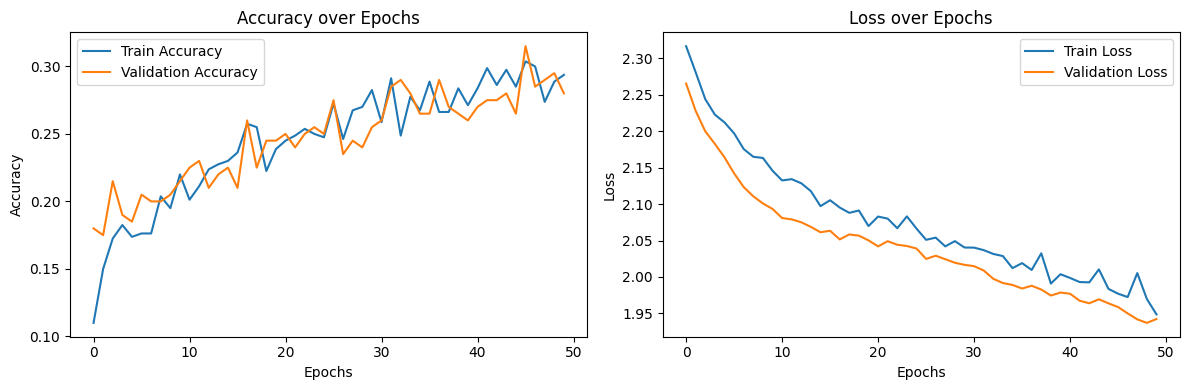

In [18]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)

plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Accuracy over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [20]:
y_pred = model.predict(X_test)

y_pred_classes = y_pred.argmax(axis=1)
y_true = y_test_cat.argmax(axis=1)

print(classification_report(y_true, y_pred_classes))

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
              precision    recall  f1-score   support

           0       0.48      0.42      0.45        33
           1       0.08      0.06      0.07        17
           2       0.30      0.36      0.33        22
           3       0.31      0.18      0.23        22
           4       0.00      0.00      0.00        22
           5       0.28      0.50      0.36        24
           6       0.28      0.29      0.29        17
           7       0.00      0.00      0.00        10
           8       0.36      0.26      0.30        19
           9       0.23      0.50      0.32        14

    accuracy                           0.28       200
   macro avg       0.23      0.26      0.23       200
weighted avg       0.26      0.28      0.26       200



In [22]:
# Example: New Match Data
new_match = {
    'venue':'Wankhede Stadium',
    'toss_winner':'Mumbai Indians',
    'toss_decision':'bat',
    'batting_first':'Mumbai Indians',
    'city':'Mumbai'
}

# Convert to DataFrame
new_df = pd.DataFrame([new_match])

#Encode using the same label encoders
for col in cat_cols:
    new_df[col] = le_dict[col].transform(new_df[col].astype(str))

#Scale
new_scaled = scaler.transform(new_df[cat_cols].values)

#Predict Probabilities
pred_prob = model.predict(new_scaled)
pred_class = np.argmax(pred_prob, axis=1)[0] 
pred_winner = le_winner.inverse_transform([pred_class])[0]

print(f"Predicted Winner:{pred_winner}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
Predicted Winner:Mumbai Indians
